Сумма фотоэлектронов на всех ФЭУ:133
Число ФЭУ (40) == Длина data ((40,))


Sampling: [CosTheta, E, R, obs, phi]
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [E, R, CosTheta, phi]


Output()

Sampling 4 chains for 50 tune and 250 draw iterations (200 + 1_000 draws total) took 62 seconds.
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


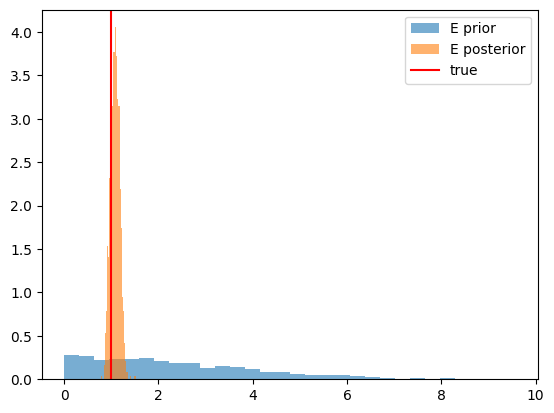

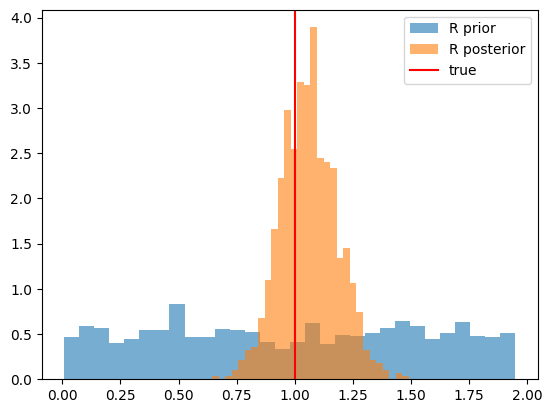

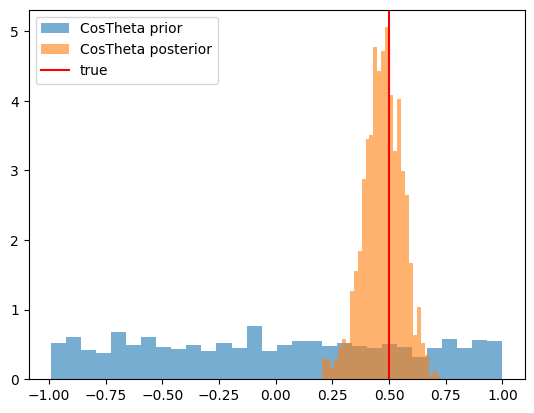

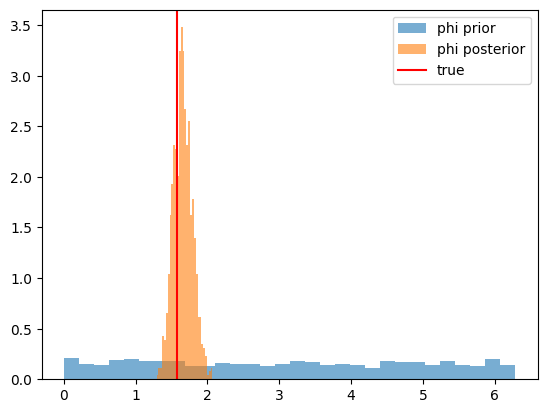

In [27]:
import os
os.environ["PYTENSOR_FLAGS"] = "cxx=" #-- не запускалось без этой правки 
import numpy as np
import pymc as pm
import pytensor.tensor as pt
import arviz as az
import matplotlib.pyplot as plt

m, cm = 1.0, 0.01
R_det = 2.0*m
N_PMT = 40
r_pmt = 10 * cm
prob = 0.5
Y = 10**4

class Detector:
    def __init__(self, R=R_det, N=N_PMT, r=r_pmt):
        self.R = R
        self.N = N
        self.r = r
        self.PMTArray = self.uniform_distribution()
    
    def uniform_distribution(self):
        i = np.arange(self.N)
        golden_ratio = (1 + np.sqrt(5)) / 2
        cosTheta = 1 - 2 * (i + 0.5) / self.N
        sinTheta = np.sqrt(1 - cosTheta**2)
        phi = 2 * np.pi * i / golden_ratio
        return self.R * np.stack([sinTheta * np.cos(phi),sinTheta * np.sin(phi),cosTheta],axis=1)

D1 = Detector()
PMT = pt.as_tensor_variable(D1.PMTArray)       
r2 = r_pmt**2

#затравочные данные 
def generate_observed(E_true, origin_true):
    # np.random.seed(1)
    n_ph = int(E_true * Y)
    origin = np.asarray(origin_true)
    
    phi = np.random.uniform(0, 2*np.pi, n_ph)
    cos_th = np.random.uniform(-1, 1, n_ph)
    sin_th = np.sqrt(1 - cos_th**2)
    dirs = np.stack([sin_th*np.cos(phi), sin_th*np.sin(phi), cos_th], axis=1)
    
    dot = dirs @ origin
    t = -dot + np.sqrt( R_det**2 - np.dot(origin, origin) + dot**2)
    points = origin + dirs * t[:, None]
    
    cos = (points @ D1.PMTArray.T) / R_det**2
    hits = (cos > np.cos(r_pmt / R_det)).sum(axis=0)
    return np.random.poisson(prob * hits)

# Семплирование отклика на ФЭУ при этих условиях
E_true = 1
R_true=1
phi_true=np.pi/2
CosTh_true=np.cos(np.pi/3)
origin_true = np.array([R_true*np.sqrt(1-CosTh_true**2)*np.cos(phi_true), R_true*np.sqrt(1-CosTh_true**2)*np.sin(phi_true), R_true*CosTh_true])
data = generate_observed(E_true, origin_true)

print(f"Сумма фотоэлектронов на всех ФЭУ:{data.sum()}")
print(f"Число ФЭУ ({D1.N}) == Длина data ({data.shape})")


with pm.Model() as model:
    #априорные распределения 
    E = pm.HalfNormal("E", sigma=3.0)
    R = pm.Uniform("R", lower=0.0, upper=1.95)
    CosTheta = pm.Uniform("CosTheta", lower=-1.0, upper=1.0)
    phi = pm.Uniform("phi", lower=0.0, upper=2*np.pi)
    SinTheta = pt.sqrt(1 - CosTheta**2)
    origin = pt.stack([R * SinTheta * pt.cos(phi),R * SinTheta * pt.sin(phi),R * CosTheta])
    
    
    vec = PMT - origin[None, :]                    
    d = pt.sqrt(pt.sum(vec**2, axis=1))    
    cos_gamma = pt.sum(vec * PMT / R_det, axis=1) / d
    cos_gamma = pt.clip(cos_gamma, 0.0, 1.0)
    Omega = np.pi * r2 * cos_gamma / (d**2)        
    frac = Omega / (4 * np.pi)
    
    mu = Y * E * prob * frac                         
    
    #правдоподобие
    pm.Poisson("obs", mu=mu, observed=data)


with model:
    prior=pm.sample_prior_predictive(draws=1000).prior
    posterior=pm.sample(draws=250, tune=50, chains=4).posterior


true_vals = {
    "E": E_true,
    "R": R_true,
    "CosTheta": CosTh_true,
    "phi": phi_true}

for name in ["E", "R", "CosTheta", "phi"]:
    s_pri=prior[name].values.ravel()
    s_post=posterior[name].values.ravel()
    plt.hist(s_pri, bins=30, density=True, alpha=0.6,label=f'{name} prior')
    plt.hist(s_post, bins=30, density=True, alpha=0.6,label=f'{name} posterior')
    plt.axvline(true_vals[name],color="red", label="true")
    plt.legend()
    plt.show()
